# Selecting a Decision Threshold by Maximum F1

Goal: **use training cross-validation to select the threshold maximizing F1, which combines precision and recall**. The test set is not used to select the threshold. Run the cells in order or select **Run All**.

Model type is still selected by mean scaffold-CV Average Precision. We then select its decision threshold using training out-of-fold scores from the selected model.

This test set has already been inspected. The comparison here is descriptive and **is not a new independent validation**.

**Historical F1 policy:** this notebook reconstructs the F1 comparison even when the app uses another policy. See `04_precision_policy_en.ipynb` for the current precision policy.

**Saved baseline:** this notebook uses `herg_precision_baseline.joblib` when available to preserve the original comparison. See `05_model_improvement_en.ipynb` for the new model search.

## 1. What are out-of-fold (OOF) predictions?

The training partition is divided into scaffold CV folds. Each model fits the other folds and scores the held-out fold. Every training row receives one OOF score from a model that did not train on that row or its scaffold.

Below, we verify that OOF rows cover the training partition, contain no test rows, and assign each scaffold to one validation fold. Run the updated `make train` first.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, average_precision_score)

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open from the project root or notebooks directory.")
sys.path.insert(0, str(ROOT))
from src.modeling import select_f1_threshold
from src.molecules import scaffold_key
baseline_path = ROOT / "models/herg_precision_baseline.joblib"
path = baseline_path if baseline_path.is_file() else ROOT / "models/herg_model.joblib"
if not path.is_file():
    raise FileNotFoundError("Run make train first.")
a = joblib.load(path)  # Only load your own trusted artifact.
if "oof_predictions" not in a:
    raise ValueError("Run the updated make train, then Run All again.")
data_path = ROOT / "data/raw/herg_karim.csv"
assert sha256(data_path.read_bytes()).hexdigest() == a["dataset_sha256"], "Dataset changed; retrain first."
oof = a["oof_predictions"].copy()
test = a["test_predictions"].copy()
assert oof.row_index.is_unique
assert set(oof.row_index) == set(a["train_indices"])
assert set(oof.row_index).isdisjoint(test.row_index)
assert oof.groupby("scaffold").fold.nunique().eq(1).all()
assert set(oof.scaffold).isdisjoint(test.scaffold)
assert oof.score.notna().all()
selected = select_f1_threshold(oof.label, oof.score)
threshold = selected["threshold"]
# Reconstruct the historical F1 policy independently of the active app policy.
test["threshold_prediction"] = (test.score >= threshold).astype(int)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
display(pd.Series({"Model": a["model_name"], "OOF rows": len(oof), "Test rows": len(test),
    "CV folds": a["cv_folds"], "Selected threshold": threshold,
    "OOF F1 at selected threshold": selected["f1"]}, name="Selection").to_frame())

,Selection
Model,Random forest
OOF rows,10765
Test rows,2680
CV folds,5
Selected threshold,0.42255
OOF F1 at selected threshold,0.795495


## 2. F1 versus threshold, using training OOF scores only

**F1 = 2 × precision × recall / (precision + recall)**. A high F1 requires both to be reasonably high. It does not assign financial or medical costs to errors and does not directly use true negatives.

We evaluate thresholds at all distinct OOF scores, assigning the inhibitor class when `score >= threshold`. Ties in maximum F1 prefer the threshold closest to 0.5, then the higher threshold.

The orange line is the selected threshold. The right chart shows how precision and recall change. The best OOF F1 is **a selection estimate**, not an independent evaluation: the same CV was also used to select model type.

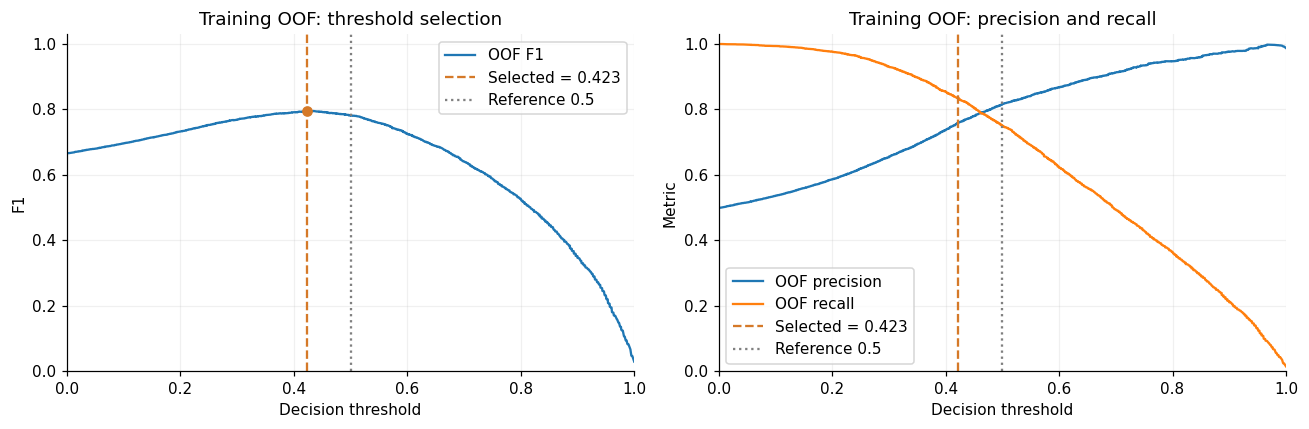

,Selected on training OOF
threshold,0.42255
criterion,f1
source,training_scaffold_oof
precision,0.760169
recall,0.834263
f1,0.795495


In [2]:
precision, recall, thresholds = precision_recall_curve(oof.label, oof.score)
precision, recall = precision[:-1], recall[:-1]
f1 = np.divide(2 * precision * recall, precision + recall,
               out=np.zeros_like(precision), where=(precision + recall) > 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(thresholds, f1, label="OOF F1")
axes[0].scatter(threshold, selected["f1"], color="#d57928", zorder=4)
axes[0].set(ylabel="F1", title="Training OOF: threshold selection")
axes[1].plot(thresholds, precision, label="OOF precision")
axes[1].plot(thresholds, recall, label="OOF recall")
axes[1].set(ylabel="Metric", title="Training OOF: precision and recall")
for ax in axes:
    ax.axvline(threshold, color="#d57928", linestyle="--", label=f"Selected = {threshold:.3f}")
    ax.axvline(0.5, color="gray", linestyle=":", label="Reference 0.5")
    ax.set(xlabel="Decision threshold", xlim=(0, 1), ylim=(0, 1.03))
    ax.legend()
fig.tight_layout()
plt.show()
display(pd.Series(selected, name="Selected on training OOF").to_frame())

## 3. Same test scores, two decision rules

After fixing the threshold, we compare the original classifier's `predict` output with the selected-threshold output. Both use test scores from the same training-fitted model, before the all-data demo refit. The original binary classifier may choose class 0 at a score tie of 0.5; the new rule explicitly uses `>=`.

**AP and ROC-AUC do not change when only the threshold changes**, because score rankings remain the same. Precision, recall, F1, FP, and FN can change. Maximizing OOF F1 does not guarantee improved test F1.

,Precision,Recall,F1,TN,FP,FN,TP,AP (same scores)
Rule,,,,,,,,
Original classifier,0.8436,0.7675,0.8037,1147,191,312,1030,0.8926
OOF F1 threshold,0.7799,0.8368,0.8073,1021,317,219,1123,0.8926


,Change: selected minus original
Precision,-0.0637
Recall,0.0693
F1,0.0036
TN,-126.0000
FP,126.0000
FN,-93.0000
TP,93.0000
AP (same scores),0.0000


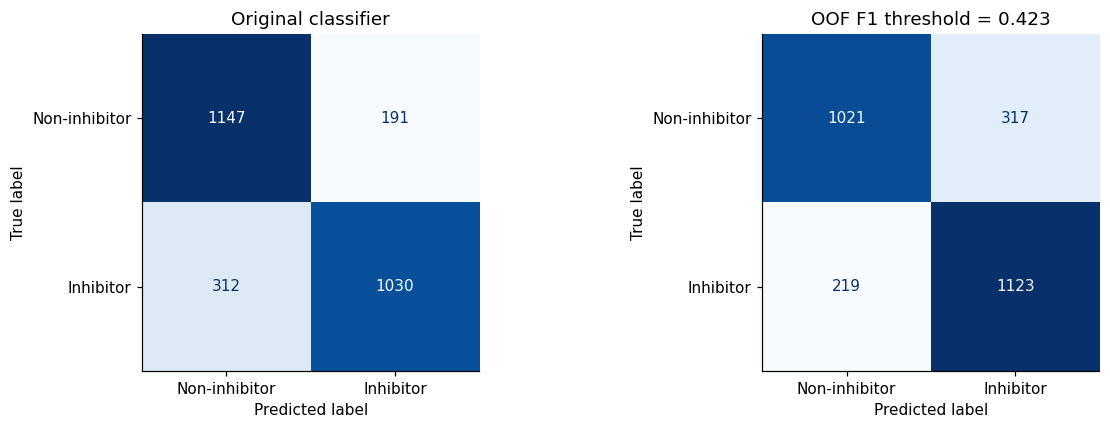

In [3]:
rows = []
for name, prediction in [("Original classifier", test.prediction), ("OOF F1 threshold", test.threshold_prediction)]:
    tn, fp, fn, tp = confusion_matrix(test.label, prediction, labels=[0, 1]).ravel()
    rows.append({"Rule": name, "Precision": precision_score(test.label, prediction, zero_division=0),
        "Recall": recall_score(test.label, prediction, zero_division=0),
        "F1": f1_score(test.label, prediction, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "AP (same scores)": average_precision_score(test.label, test.score)})
comparison = pd.DataFrame(rows).set_index("Rule")
assert np.isclose(comparison.loc["OOF F1 threshold", "F1"], f1_score(test.label, test.score >= threshold))
display(comparison.round(4))
display((comparison.loc["OOF F1 threshold"] - comparison.loc["Original classifier"])
        .rename("Change: selected minus original").to_frame().round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, title, prediction in zip(axes, ["Original classifier", f"OOF F1 threshold = {threshold:.3f}"],
                                 [test.prediction, test.threshold_prediction]):
    ConfusionMatrixDisplay.from_predictions(test.label, prediction, labels=[0, 1],
        display_labels=["Non-inhibitor", "Inhibitor"], cmap="Blues", ax=ax,
        colorbar=False, values_format="d")
    ax.set_title(title)
    ax.grid(False)
fig.tight_layout()
plt.show()

### Interpreting this run

The threshold moved **from around 0.5 to 0.42255**. Its training OOF F1 is approximately **0.7955**. On the same test set, F1 increased slightly, **0.8037 → 0.8073**, but precision fell, **84.4% → 78.0%**, while recall increased, **76.8% → 83.7%**.

The selected threshold detected **93 additional inhibitors**, but introduced **126 additional false alarms**. Total errors increased even though F1 improved slightly: F1 does not optimize overall accuracy or minimize total mistakes. This is the trade-off of the chosen objective. These numbers refer to the saved run.

## 4. Which compounds changed classification?

Below are the first 20 rows whose classification changed. The summary counts how many errors were corrected and how many new errors were introduced. A selected threshold is not automatically better for every compound.

In [4]:
changed = test[test.prediction != test.threshold_prediction].copy()
changed["original_correct"] = changed.prediction.eq(changed.label)
changed["selected_correct"] = changed.threshold_prediction.eq(changed.label)
display(pd.Series({"Changed classifications": len(changed),
    "Errors corrected": int((~changed.original_correct & changed.selected_correct).sum()),
    "New errors": int((changed.original_correct & ~changed.selected_correct).sum())}, name="Count").to_frame())
columns = [c for c in ["compound_id", "row_index", "label", "score", "prediction", "threshold_prediction"] if c in changed]
display(changed[columns].head(20))

,Count
Changed classifications,219
Errors corrected,93
New errors,126


,compound_id,row_index,label,score,prediction,threshold_prediction
2,18,8,1,0.480000,0,1
15,140,65,1,0.456667,0,1
37,407,190,1,0.465835,0,1
48,470,217,0,0.450000,0,1
53,525,245,1,0.463333,0,1
60,567,267,0,0.426667,0,1
65,640,299,0,0.426667,0,1
88,822,389,0,0.450000,0,1
91,857,402,1,0.483333,0,1
102,961,462,1,0.459168,0,1


## 5. How the app uses this threshold

When the F1 policy is active, training stores its selected threshold and OOF data in the model artifact. The app uses `score >= decision_threshold` for new predictions and displays the threshold. Its evaluation section separately labels original-rule and selected-threshold test results.

The app model is subsequently refitted on the full dataset. We transfer the same threshold to that model, but refitting can change score distributions. Test metrics describe the training-fitted evaluation model and do not guarantee future demo performance.